#### **Variational Autoencoders**

VAEs are a kind of generative model that's especially appropiate for the task of image editing via concept vectors. In technical terms, it encodes the input samples into two parameters in a latent space of representations then randomly sample a point from the latent normal distribution that's assumed to generate the input image. Finally it maps this point in the latent space back to the original input image.


So a VAE, consist of an encoder layer, a latent space representation and a decoder layer. Let's code it one by one.

#### **VAE Encoder Network**

In [ ]:
import keras
from keras import layers
from keras import backend as K
from keras.models import Model
import numpy as np

img_shape = (28, 28, 1)
batch_size = 16
latent_dim = 2

input_img = keras.Input(shape=img_shape)

x = layers.Conv2D(32, 3, activation='relu', padding='same')(input_img)
x = layers.Conv2D(64, 3, activation='relu', padding='same', strides=(2, 2))(x)
x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
shape_before_flattening = K.int_shape(x)

x = layers.Flatten()(x)
x = layers.Dense(32, activation='relu')(x)

### The input to the latent space is parameterized by a mean and a log variance vector
z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)

2026-07-05 19:39:20.827591: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2026-07-05 19:39:20.827609: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-07-05 19:39:22.722956: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2026-07-05 19:39:22.723020: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2026-07-05 19:39:22.723068: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: lib

#### **Latent space sampling function**

In [2]:
def sampling(args):
    z_mean, z_log_var = args
    epsilon = K.random_normal(shape=(K.shape(z_mean)[0], latent_dim),
                              mean=0., stddev=1.)
    return z_mean + K.exp(z_log_var) * epsilon

z = layers.Lambda(sampling)([z_mean, z_log_var])

#### **VAE Decoder**

mapping latent space points to images

In [3]:
decoder_input = layers.Input(K.int_shape(z)[1:]) # input where we'll feed z

x = layers.Dense(np.prod(shape_before_flattening[1:]), activation='relu')(decoder_input) # upsamples the input
x = layers.Reshape(shape_before_flattening[1:])(x) # Reshape z into a feature map of the same size as the last convolutional layer of the encoder

# Now we can use Conv2DTranspose to reverse the operations of Conv2D
x = layers.Conv2DTranspose(32, 3, activation='relu', padding='same', strides=(2, 2))(x)
x = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)

decoder = Model(decoder_input, x) # The decoder model takes the latent vector z as input and outputs the reconstructed image.

z_decoded = decoder(z) # The output of the decoder is the reconstructed image.

However, there is a problem. The dual loss of a VAE doesn't fit the traditional expectation of a sample-wise function of the form `loss(input, target)`. Thus we'll setup the loss by writing a custom layer that internally uses the built_in `add_loss` layer method to create an aribitrary loss.

In [4]:
### Custom layer to calculate the VAE loss
class CustomVariationalLayer(keras.layers.Layer):
    def __init__(self, **kwargs):
        super(CustomVariationalLayer, self).__init__(**kwargs)
        self.bce_loss_fn = keras.losses.BinaryCrossentropy(from_logits=False, reduction='none')

    def call(self, inputs): ### implement the call method to compute the loss and add it to the layer
        x = inputs[0]
        z_decoded = inputs[1]
        z_mean = inputs[2]
        z_log_var = inputs[3]

        x = K.flatten(x)
        z_decoded = K.flatten(z_decoded)
        xent_loss = self.bce_loss_fn(x, z_decoded)
        kl_loss = - 5e-4 * K.sum(
            1 + z_log_var - K.square(z_mean) - K.exp(z_log_var), axis=-1)
        loss = K.mean(xent_loss + kl_loss)

        self.add_loss(loss)
        return x # we don't use the output of this layer, but it could be used for monitoring the loss during training


y = CustomVariationalLayer()([input_img, z_decoded, z_mean, z_log_var]) # The output of the custom layer is the original input image, but it also computes the loss.


#### **Training the VAE**

In [5]:
from keras.datasets import mnist

vae = Model(input_img, y) # The VAE model takes the input image and outputs the original image, but it also computes the loss.
vae.compile(optimizer='rmsprop', loss=None) # We don't need to specify a loss function, because the custom layer computes the loss.
vae.summary() # Print the summary of the model architecture.

(x_train, _), (x_test, _) = mnist.load_data() # Load the MNIST dataset
x_train = x_train.astype('float32') / 255. # Normalize the pixel values
x_train = np.reshape(x_train, (len(x_train), 28, 28, 1)) # Reshape the data to have a single channel
x_test = x_test.astype('float32') / 255.
x_test = np.reshape(x_test, (len(x_test), 28, 28, 1))

vae.fit(x=x_train, y=None, shuffle=True, epochs=10, batch_size=batch_size, validation_data=(x_test, None)) # Train the VAE model

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 28, 28, 1)]  0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 28, 28, 32)   320         ['input_1[0][0]']                
                                                                                                  


 conv2d_1 (Conv2D)              (None, 14, 14, 64)   18496       ['conv2d[0][0]']                 
                                                                                                  
 conv2d_2 (Conv2D)              (None, 14, 14, 64)   36928       ['conv2d_1[0][0]']               
                                                                                                  
 conv2d_3 (Conv2D)              (None, 14, 14, 64)   36928       ['conv2d_2[0][0]']               
                                                                                                  
 flatten (Flatten)              (None, 12544)        0           ['conv2d_3[0][0]']               
                                                                                                  
 dense (Dense)                  (None, 32)           401440      ['flatten[0][0]']                
                                                                                                  
 dense_1 (

One such a model is trained on MNIST, we can use the decoder network to turn arbitrary latent space vectors into images.

1/1 [==============================] - 0s 13ms/step


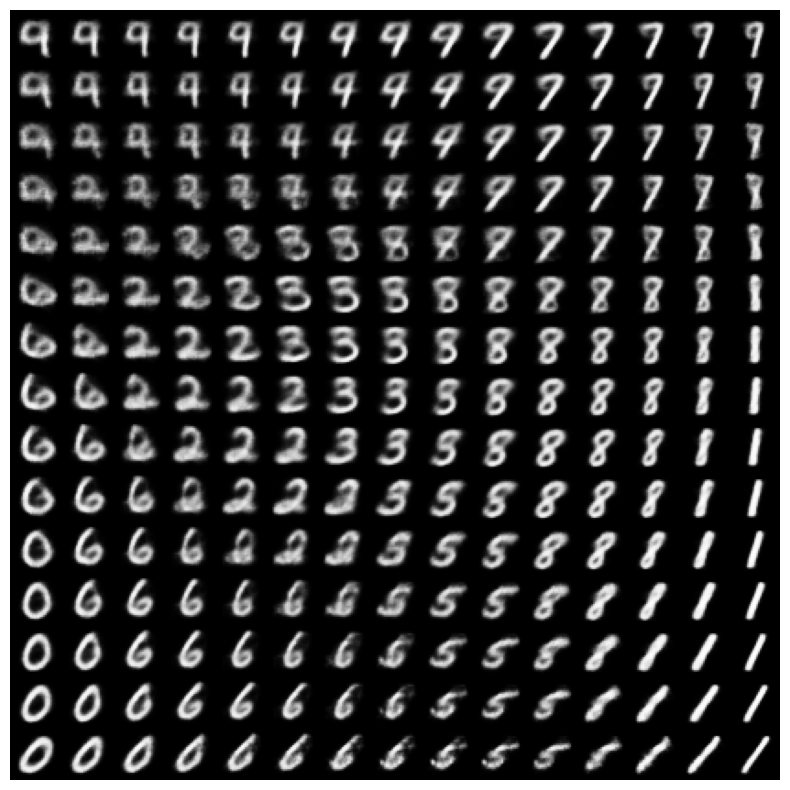

In [7]:
### Sample a griod of points from the 2D latent space and decoding them to images

import matplotlib.pyplot as plt
from scipy.stats import norm

n = 15  # figure with 15x15 digits
digit_size = 28
figure = np.zeros((digit_size * n, digit_size * n)) # Create an empty figure to hold the generated images
# We will sample n points within [-15, 15]
# and decode them to images
grid_x = norm.ppf(np.linspace(0.05, 0.95, n)) # Use the percent point function (inverse of cdf) to get the grid of points
grid_y = norm.ppf(np.linspace(0.05, 0.95, n)) # transform linearly spaced coordinates to produce values of the latent variable z (because the prior of the latent space is Gaaussian)

for i, yi in enumerate(grid_x):
    for j, xi in enumerate(grid_y):
        z_sample = np.array([[xi, yi]]) # Create a sample from the latent space
        x_decoded = decoder.predict(z_sample) # Decode the sample to an image
        digit = x_decoded[0].reshape(digit_size, digit_size) # Reshape the decoded image to 28x28
        figure[i * digit_size: (i + 1) * digit_size,
               j * digit_size: (j + 1) * digit_size] = digit # Place the decoded image in the figure    
        

plt.figure(figsize=(10, 10)) # Create a figure to display the generated images
plt.imshow(figure, cmap='Greys_r') # Display the figure with the generated images
plt.axis('off') # Turn off the axis
plt.show() # Show the figure

The grid of sampled digits shows a completely continuous distribution of the different digit classes, with one digit morphing into another as you follow a path through latent space. Specific directions in this space have a meaning for example, there's a direction for "four-ness", "one-ness" and so on.